<a href="https://colab.research.google.com/github/DLO-4-ya/Probabilidad-y-Estadistica/blob/main/Unidad_5/proyecto_U5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
sns.set_theme(style="whitegrid")

In [13]:
def analizar_grupo(nombre_archivo, nombre_grupo):
    print(f" analisis para el {nombre_grupo.upper()}")
    print(f"---------------------------------------------------")
    df = pd.read_csv(nombre_archivo)
    print("\n--- primeras filas del dataset ---")
    display(df.head())
    print("\n--- descripción estadística basica ---")
    display(df.describe())
    x = df.iloc[:, 0].values.reshape(-1, 1)
    y = df.iloc[:, 1].values
    modelo = LinearRegression()
    modelo.fit(x, y)
    pendiente = modelo.coef_[0]
    intercepto = modelo.intercept_
    y_pred = modelo.predict(x)
    print(f"\n--- modelo de regresión lineal ---")
    print(f"ecuación de la recta: calificación = {pendiente:.4f} * (horas) + {intercepto:.4f}")
    correlacion = np.corrcoef(df.iloc[:, 0], df.iloc[:, 1])[0, 1]
    r2 = r2_score(y, y_pred)
    print(f"coeficiente de correlación de parson (r): {correlacion:.4f}")
    print(f"coeficiente de determinación (R²): {r2:.4f}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(y, kde=True, ax=axes[0], color='skyblue', bins=10)
    axes[0].set_title(f'histograma de calificaciones - {nombre_grupo}')
    axes[0].set_xlabel('calificación final')
    axes[0].set_ylabel('frecuencia')
    sns.scatterplot(x=df.iloc[:, 0], y=df.iloc[:, 1], ax=axes[1], color='blue', label='datos reales')
    axes[1].plot(x, y_pred, color='red', linewidth=2, label=f'linea: y = {pendiente:.2f}x + {intercepto:.2f}')
    axes[1].set_title(f'regresión lineal - {nombre_grupo}')
    axes[1].set_xlabel(df.columns[0])
    axes[1].set_ylabel(df.columns[1])
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    print("\n" + "="*50 + "\n")

 analisis para el GRUPO 1
---------------------------------------------------

--- primeras filas del dataset ---


,HorasEstudio,Calificacion
0,20.00,75.94
1,15.60,87.48
2,17.91,79.40
3,20.00,73.37
4,20.00,83.75



--- descripción estadística basica ---


,HorasEstudio,Calificacion
count,50.000000,50.00000
mean,14.352000,83.78820
std,4.219174,7.83389
min,3.790000,68.46000
25%,12.032500,78.03500
50%,14.600000,84.49000
75%,17.715000,88.09000
max,20.000000,100.00000



--- modelo de regresión lineal ---
ecuación de la recta: calificación = -0.1061 * (horas) + 85.3107
coeficiente de correlación de parson (r): -0.0571
coeficiente de determinación (R²): 0.0033


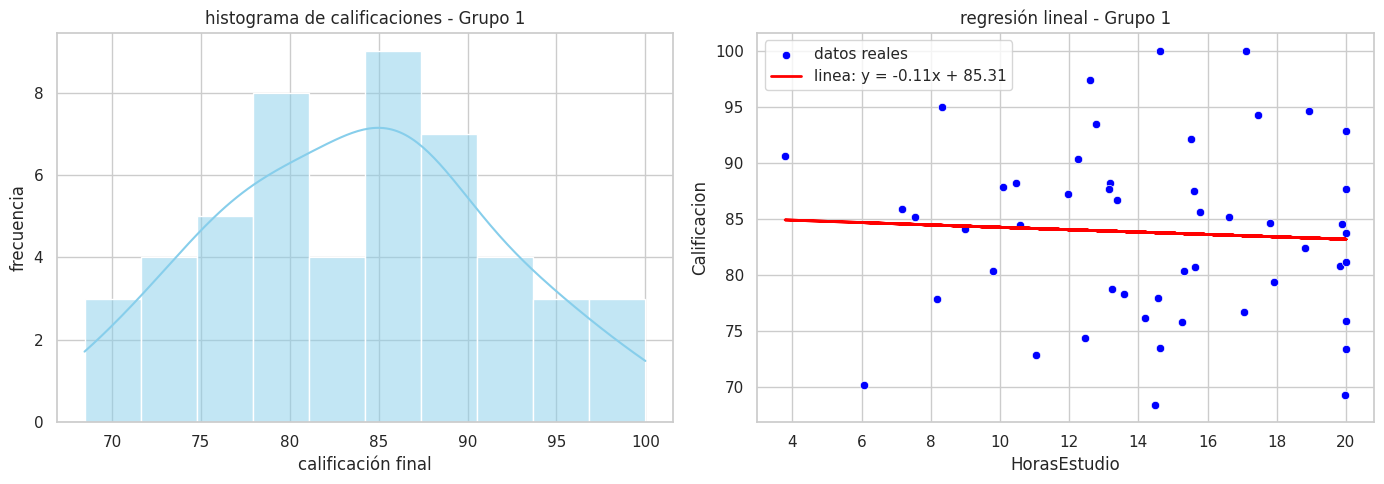

In [14]:
analizar_grupo("grupo1.csv", "Grupo 1")

 analisis para el GRUPO 2
---------------------------------------------------

--- primeras filas del dataset ---


,HorasEstudio,Calificacion
0,3.79,40.0
1,6.08,26.1
2,7.17,29.0
3,7.54,31.9
4,8.18,34.8



--- descripción estadística basica ---


,HorasEstudio,Calificacion
count,50.000000,50.000000
mean,14.352000,75.912000
std,4.219174,20.668922
min,3.790000,26.100000
25%,12.032500,63.500000
50%,14.600000,78.550000
75%,17.715000,93.300000
max,20.000000,99.000000



--- modelo de regresión lineal ---
ecuación de la recta: calificación = 4.2227 * (horas) + 15.3075
coeficiente de correlación de parson (r): 0.8620
coeficiente de determinación (R²): 0.7430


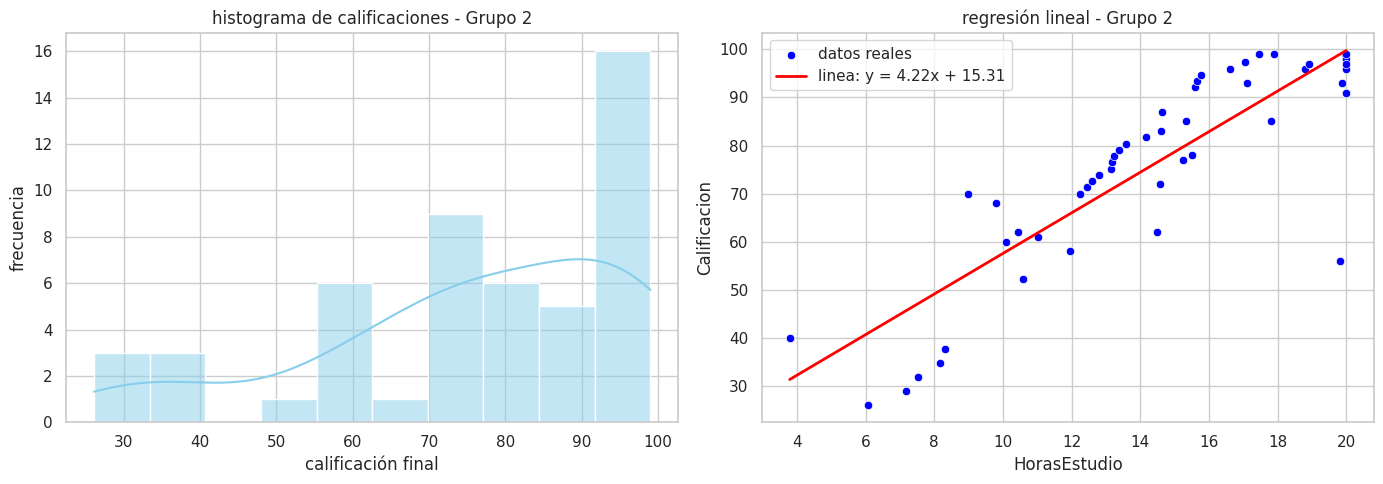

In [15]:
analizar_grupo("grupo2.csv", "Grupo 2")

 analisis para el GRUPO 3
---------------------------------------------------

--- primeras filas del dataset ---


,HorasEstudio,Calificacion
0,3.79,15.0
1,6.08,26.1
2,7.17,29.0
3,7.54,31.9
4,8.18,34.8



--- descripción estadística basica ---


,HorasEstudio,Calificacion
count,50.000000,50.000000
mean,14.352000,75.968000
std,4.219174,23.668867
min,3.790000,15.000000
25%,12.032500,61.000000
50%,14.600000,84.950000
75%,17.715000,94.375000
max,20.000000,99.000000



--- modelo de regresión lineal ---
ecuación de la recta: calificación = 5.2857 * (horas) + 0.1081
coeficiente de correlación de parson (r): 0.9422
coeficiente de determinación (R²): 0.8878


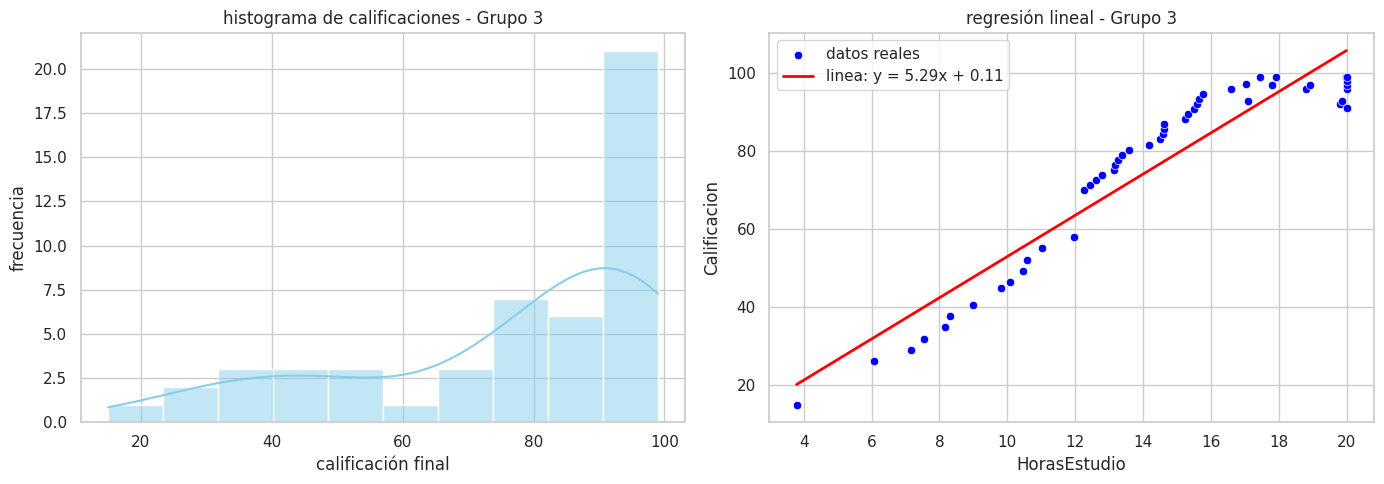

In [16]:
analizar_grupo("grupo3.csv", "Grupo 3")

###Interpretación del coeficiente de regresión:
Indica cuánto cambia en promedio la calificación final por cada hora adicional que el estudiante dedica al estudio. (Por ejemplo, si la pendiente es $2.5$, significa que por cada hora extra de estudio, la calificación aumenta en promedio $2.5$ puntos).



###Interpretación del coeficiente de correlación:
Fuerza: Si está cerca de 1 o -1, la relación es fuerte; si está cerca de $0$, es débil.
Dirección: Si es positivo, a mayor tiempo de estudio mayor calificación; si es negativo, ocurre lo contrario.



###Significancia estadística del modelo:
 Puedes apoyarte en el coeficiente de determinación R elevado a 2 impreso en el código. Un valor de R elevado a 2 cercano a 1 indica que el modelo explica muy bien la variabilidad de los datos.



### Confiabilidad para predecir:
 Si los puntos en el diagrama de dispersión están muy pegados a la línea roja de regresión, el modelo es altamente confiable para hacer predicciones; si están muy dispersos por todo el gráfico, las predicciones tendrán un margen de error considerable.